# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Wahyu Damai Saputra
- NIM   : 241011400361
- Kelas : Reg C

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 61  # dua digit terakhir NIM 241011400361

def train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def mae(y_true, y_pred):
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

def mse(y_true, y_pred):
    return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score_np(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - np.sum((y_true - y_pred) ** 2) / denominator if denominator != 0 else np.nan

def confusion_matrix_np(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    return np.array([[np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
                     [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]])

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix_np(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return accuracy, cm, precision, recall, f1

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.theta = np.linalg.pinv(np.c_[np.ones(len(X)), X]) @ y
        self.intercept_ = self.theta[0]
        self.coef_ = self.theta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.x_mean, self.x_std = X.mean(axis=0), X.std(axis=0)
        self.x_std[self.x_std == 0] = 1
        Xs = (X - self.x_mean) / self.x_std
        self.y_mean, self.y_std = y.mean(), y.std()
        if self.y_std == 0: self.y_std = 1
        ys = (y - self.y_mean) / self.y_std
        Xb = np.c_[np.ones(len(Xs)), Xs]
        theta = np.zeros(Xb.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            error = Xb @ theta - ys
            theta -= self.learning_rate * (2 / len(ys)) * (Xb.T @ error)
            self.loss_history.append(np.mean((Xb @ theta - ys) ** 2))
        self.intercept_ = self.y_mean + self.y_std * (theta[0] - np.sum(theta[1:] * self.x_mean / self.x_std))
        self.coef_ = self.y_std * theta[1:] / self.x_std
        return self
    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        self.x_mean, self.x_std = X.mean(axis=0), X.std(axis=0)
        self.x_std[self.x_std == 0] = 1
        Xs = (X - self.x_mean) / self.x_std
        Xb = np.c_[np.ones(len(Xs)), Xs]
        theta = np.zeros(Xb.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            p = sigmoid(Xb @ theta)
            grad = Xb.T @ (p - y) / len(y)
            theta -= self.learning_rate * grad
            p = np.clip(sigmoid(Xb @ theta), 1e-12, 1 - 1e-12)
            self.loss_history.append(-np.mean(y * np.log(p) + (1-y) * np.log(1-p)))
        self.intercept_ = theta[0] - np.sum(theta[1:] * self.x_mean / self.x_std)
        self.coef_ = theta[1:] / self.x_std
        return self
    def predict_proba(self, X):
        z = self.intercept_ + np.asarray(X, dtype=float) @ self.coef_
        p = sigmoid(z)
        return np.c_[1-p, p]
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

print("Library siap digunakan. RANDOM_STATE =", RANDOM_STATE)


Library siap digunakan. RANDOM_STATE = 61


In [2]:
# Fungsi train_test_split sudah dibuat di sel sebelumnya dan menggunakan NumPy.

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


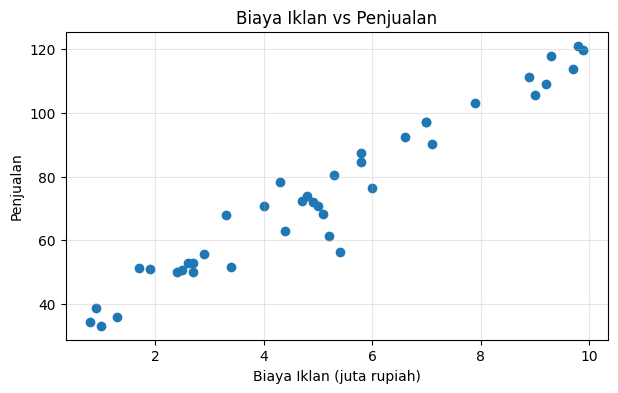

In [3]:
# Jawaban A1
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris data:", len(ads))

X_ads = ads[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X_ads[:, 0], y_ads)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta rupiah)")
plt.ylabel("Penjualan")
plt.grid(True, alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
linear_model = LinearRegression().fit(X_train, y_train)
b = linear_model.intercept_
m = linear_model.coef_[0]
print(f"Intercept (b): {b:.4f}")
print(f"Koefisien (m): {m:.4f}")
print(f"Persamaan regresi: ŷ = {b:.4f} + {m:.4f}X")


Intercept (b): 27.8952
Koefisien (m): 9.0943
Persamaan regresi: ŷ = 27.8952 + 9.0943X


**Jawaban A3 (interpretasi):**

Koefisien bernilai positif, jadi biaya iklan dan penjualan cenderung bergerak searah. Berdasarkan model, setiap tambahan biaya iklan sebesar Rp1 juta diperkirakan berkaitan dengan kenaikan penjualan sekitar nilai koefisien \(m\) dalam satuan penjualan dataset. Ini menunjukkan hubungan pada data, tetapi tidak otomatis membuktikan bahwa iklan adalah satu-satunya penyebab kenaikan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    return {"MAE": mae(y_true, y_pred), "MSE": mse(y_true, y_pred),
            "RMSE": rmse(y_true, y_pred), "R²": r2_score_np(y_true, y_pred)}

pred_train = linear_model.predict(X_train)
pred_test = linear_model.predict(X_test)
metrics_table = pd.DataFrame([
    {"Data": "Training", **regression_metrics(y_train, pred_train)},
    {"Data": "Testing", **regression_metrics(y_test, pred_test)}
]).set_index("Data")
display(metrics_table.round(4))


,MAE,MSE,RMSE,R²
Data,,,,
Training,4.6054,38.0581,6.1691,0.9437
Testing,4.3607,28.7447,5.3614,0.9383


**Jawaban A4 (analisis):**

MAE menunjukkan rata-rata selisih absolut prediksi, MSE memberi penalti lebih besar pada kesalahan besar, sedangkan RMSE kembali ke satuan target. Nilai R² menunjukkan seberapa baik model menjelaskan variasi penjualan. Hasil testing lebih berguna untuk memperkirakan kinerja pada data baru; jika hasil training jauh lebih baik daripada testing, model mungkin kurang mampu melakukan generalisasi.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

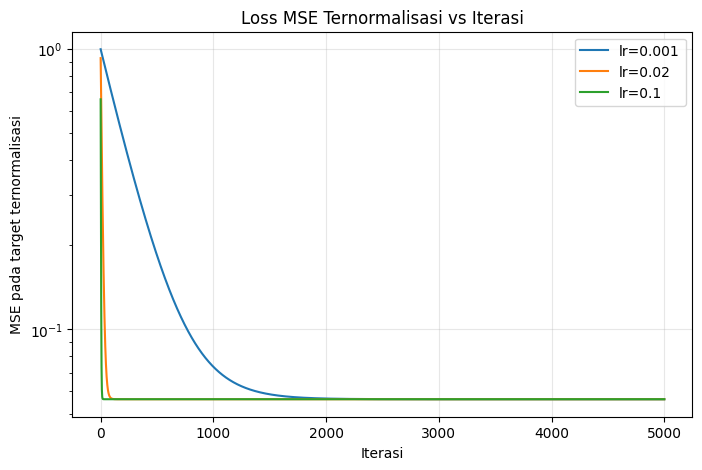

,Learning rate,Intercept,Koefisien,MSE training
0,0.001,27.8973,9.0939,38.0581
1,0.020,27.8952,9.0943,38.0581
2,0.100,27.8952,9.0943,38.0581


Normal equation: b=27.8952, m=9.0943


In [7]:
# Jawaban A5
gd_models = {}
gd_results = []
plt.figure(figsize=(8, 5))
for lr in [0.001, 0.02, 0.1]:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model_gd
    gd_results.append({
        "Learning rate": lr,
        "Intercept": model_gd.intercept_,
        "Koefisien": model_gd.coef_[0],
        "MSE training": mse(y_train, model_gd.predict(X_train))
    })
    plt.plot(model_gd.loss_history, label=f"lr={lr}")
plt.title("Loss MSE Ternormalisasi vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE pada target ternormalisasi")
plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
display(pd.DataFrame(gd_results).round(4))
print(f"Normal equation: b={linear_model.intercept_:.4f}, m={linear_model.coef_[0]:.4f}")


**Jawaban A5 (analisis):**

Learning rate 0.001 biasanya bergerak lebih lambat menuju nilai minimum. Learning rate 0.02 umumnya memberi keseimbangan antara kecepatan dan kestabilan, sedangkan 0.1 dapat bergerak lebih cepat dan perlu diamati apakah loss tetap stabil. Pada implementasi ini fitur dan target dinormalisasi saat pelatihan agar perbandingan learning rate lebih stabil; parameter yang ditampilkan dikembalikan ke skala asli. Jika loss naik tajam atau menjadi tidak hingga, itu menandakan proses tidak konvergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

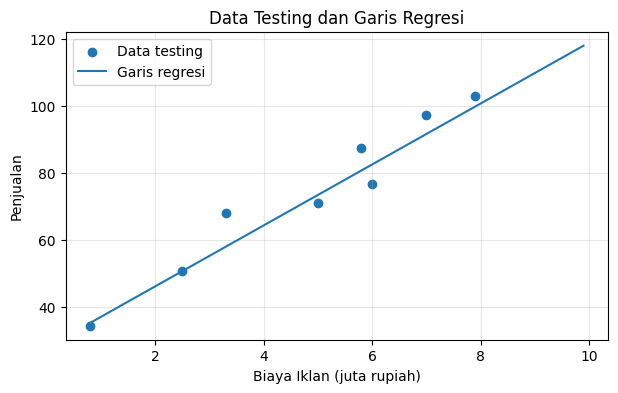

,Biaya Iklan (juta Rp),Prediksi Penjualan
0,4.5,68.819
1,7.0,91.555
2,12.0,137.027


In [8]:
# Jawaban A6
plt.figure(figsize=(7, 4))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(X_ads.min(), X_ads.max(), 200).reshape(-1, 1)
plt.plot(x_line[:, 0], linear_model.predict(x_line), label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta rupiah)")
plt.ylabel("Penjualan")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = linear_model.predict(biaya_baru)
display(pd.DataFrame({"Biaya Iklan (juta Rp)": biaya_baru[:, 0], "Prediksi Penjualan": prediksi_baru}).round(3))


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 juta dan 7 juta lebih dapat dipertimbangkan jika masih berada di dalam rentang data yang diamati. Prediksi 12 juta merupakan ekstrapolasi jika nilainya berada di luar rentang data, sehingga lebih tidak pasti. Hubungan yang terlihat pada data lama belum tentu terus berlaku pada biaya iklan yang lebih tinggi.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email per kelas:


,Jumlah
Kelas,
Bukan Spam,35
Spam,25


Shape X: (60, 2) | Shape y: (60,)


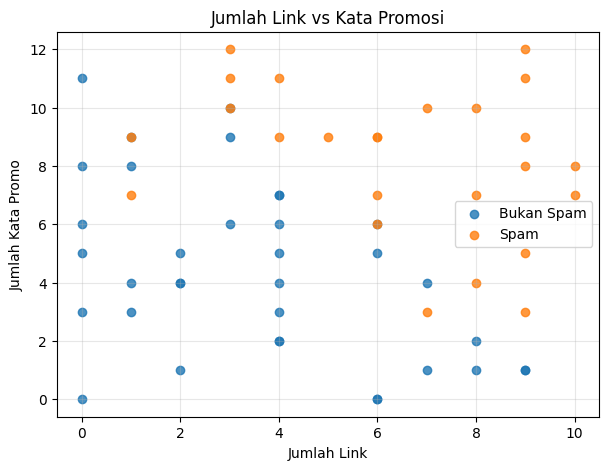

In [9]:
# Jawaban B1
email = pd.read_csv("Email_Data.csv")
display(email.head())
print("Jumlah email per kelas:")
display(email["Spam"].map({0: "Bukan Spam", 1: "Spam"}).value_counts().rename_axis("Kelas").to_frame("Jumlah"))

X_email = email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
for label, name in [(0, "Bukan Spam"), (1, "Spam")]:
    subset = email[email["Spam"] == label]
    plt.scatter(subset["JumlahLink"], subset["KataPromo"], label=name, alpha=0.8)
plt.title("Jumlah Link vs Kata Promosi")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -8.6579
Koefisien (m1, m2): [0.7371 0.7673]
P(Spam) = sigmoid(-8.6579 + (0.7371)*JumlahLink + (0.7673)*KataPromo)


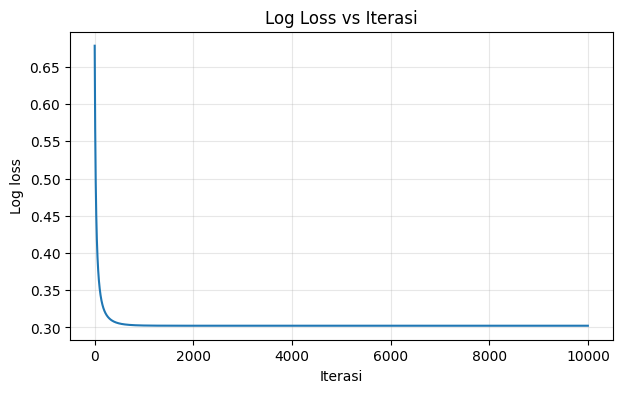

Log loss awal: 0.6783
Log loss akhir: 0.3023


In [10]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_email, y_train_email)
print("Intercept (b):", round(log_model.intercept_, 4))
print("Koefisien (m1, m2):", np.round(log_model.coef_, 4))
print(f"P(Spam) = sigmoid({log_model.intercept_:.4f} + ({log_model.coef_[0]:.4f})*JumlahLink + ({log_model.coef_[1]:.4f})*KataPromo)")

plt.figure(figsize=(7, 4))
plt.plot(log_model.loss_history)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(True, alpha=0.3)
plt.show()
print("Log loss awal:", round(log_model.loss_history[0], 4))
print("Log loss akhir:", round(log_model.loss_history[-1], 4))


**Jawaban B2 (analisis):**

Log loss yang menurun menunjukkan model semakin baik dalam menyesuaikan probabilitas prediksi dengan label data training. Jika kurva kemudian mendatar, berarti pembaruan parameter mulai stabil. Koefisien positif meningkatkan kecenderungan prediksi spam, sedangkan koefisien negatif menurunkannya ketika fitur lain dianggap tetap.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
prob_test = log_model.predict_proba(X_test_email)[:, 1]
pred_test_email = (prob_test >= 0.5).astype(int)
acc, cm, precision, recall, f1 = classification_metrics(y_test_email, pred_test_email)
print("Accuracy:", round(acc, 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))


Accuracy: 0.9333
Confusion matrix [[TN, FP], [FN, TP]]:
[[12  1]
 [ 0  2]]
Precision: 0.6667
Recall: 1.0
F1-score: 0.8


**Jawaban B3 (analisis):**

FP adalah email bukan spam yang salah ditandai sebagai spam, sehingga pesan penting bisa masuk folder spam. FN adalah email spam yang lolos dan masuk kotak masuk. Menurut saya, FP dapat sangat merugikan jika menyebabkan email penting terlewat, sedangkan FN juga mengganggu karena spam tetap diterima. Untuk penggunaan nyata, keduanya perlu diseimbangkan sesuai kebutuhan pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.6579 + (0.7371)*JumlahLink) / (0.7673)


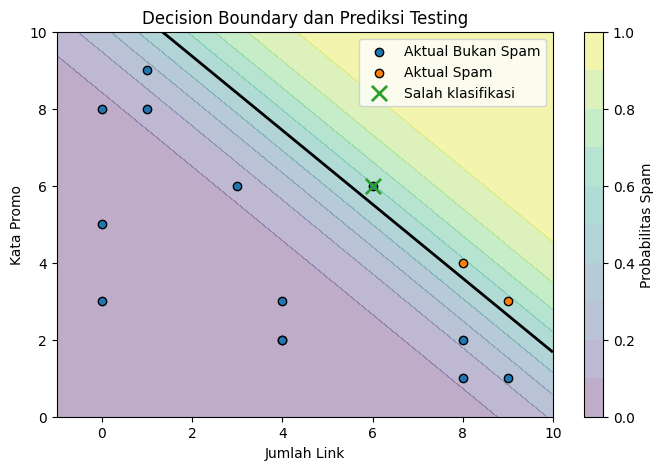

Indeks posisi data testing yang salah diklasifikasikan (mulai dari 0): [8]


In [12]:
# Jawaban B4
b = log_model.intercept_
m1, m2 = log_model.coef_
if abs(m2) > 1e-12:
    print(f"Decision boundary: KataPromo = -({b:.4f} + ({m1:.4f})*JumlahLink) / ({m2:.4f})")
else:
    print("Koefisien KataPromo mendekati nol, sehingga batas tidak dapat ditampilkan sebagai fungsi KataPromo.")

x_min, x_max = X_test_email[:, 0].min() - 1, X_test_email[:, 0].max() + 1
y_min, y_max = X_test_email[:, 1].min() - 1, X_test_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = log_model.predict_proba(grid)[:, 1].reshape(xx.shape)
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), alpha=0.35)
plt.colorbar(label="Probabilitas Spam")
for label, name in [(0, "Bukan Spam"), (1, "Spam")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], label=f"Aktual {name}", edgecolor="black")
wrong = pred_test_email != y_test_email
if wrong.any():
    plt.scatter(X_test_email[wrong, 0], X_test_email[wrong, 1], marker="x", s=120, linewidths=2, label="Salah klasifikasi")
plt.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=2)
plt.title("Decision Boundary dan Prediksi Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Kata Promo")
plt.legend()
plt.show()
print("Indeks posisi data testing yang salah diklasifikasikan (mulai dari 0):", np.where(wrong)[0].tolist())


**Jawaban B4 (analisis):**

Decision boundary adalah garis dengan probabilitas spam 0,5. Titik yang berada di sisi dengan probabilitas di atas 0,5 diprediksi sebagai spam, sedangkan sisi lainnya diprediksi bukan spam. Tanda silang pada grafik menunjukkan data testing yang prediksinya berbeda dari label sebenarnya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
threshold_results = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    acc_t, cm_t, p_t, r_t, f1_t = classification_metrics(y_test_email, pred)
    tn, fp, fn, tp = cm_t.ravel()
    threshold_results.append({
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": acc_t, "Precision": p_t, "Recall": r_t, "F1": f1_t
    })
display(pd.DataFrame(threshold_results).round(3))


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,0.3,12,1,0,2,0.933,0.667,1.0,0.8
1,0.5,12,1,0,2,0.933,0.667,1.0,0.8
2,0.7,13,0,2,0,0.867,0.000,0.0,0.0


**Jawaban B5 (analisis):**

Threshold yang lebih rendah membuat model lebih mudah menandai email sebagai spam, sehingga recall cenderung naik tetapi FP juga dapat bertambah dan precision bisa turun. Threshold yang lebih tinggi membuat model lebih berhati-hati menandai spam, sehingga precision dapat meningkat tetapi lebih banyak spam mungkin lolos. Untuk filter email, saya memilih threshold 0,5 sebagai titik awal yang seimbang, lalu menyesuaikannya berdasarkan dampak FP dan FN pada pengguna.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
threshold_pilihan = 0.5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
p_spam = log_model.predict_proba(X_baru)[:, 1]
pred_spam = (p_spam >= threshold_pilihan).astype(int)
email_baru["Probabilitas Spam"] = p_spam
email_baru["Prediksi"] = np.where(pred_spam == 1, "Spam", "Bukan Spam")
email_baru["Threshold"] = threshold_pilihan
display(email_baru.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0017,Bukan Spam,0.5
1,E2,5,6,0.4090,Bukan Spam,0.5
2,E3,9,10,0.9965,Spam,0.5
3,E4,2,11,0.7785,Spam,0.5


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk klasifikasi karena hasil akhirnya berupa kelas, misalnya spam atau bukan spam. Model menghitung skor dari fitur, lalu fungsi sigmoid mengubah skor tersebut menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:**

Normal equation menghitung parameter secara langsung menggunakan operasi matriks, tanpa proses iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient descent cocok ketika data atau jumlah fitur besar sehingga perhitungan matriks langsung menjadi mahal.

**Jawaban C3:**

Data training digunakan untuk melatih model, sedangkan data testing digunakan untuk mengukur kemampuan model pada data yang belum dilihat. Jika hanya mengukur training, hasilnya bisa terlihat bagus tetapi belum tentu berlaku pada data baru. Overfitting terjadi ketika model terlalu menyesuaikan diri pada data training sehingga performanya menurun pada data lain.

**Jawaban C4:**

Linear Regression memprediksi nilai numerik, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai asli dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa tepat probabilitas tersebut terhadap label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah.

**Jawaban C5:**

Hasil dapat berbeda karena pembagian data training dan testing atau nilai random state berbeda. Hasil juga dipengaruhi learning rate, jumlah iterasi, inisialisasi parameter, dan cara normalisasi fitur. Karena itu, perbandingan yang adil perlu memakai pembagian data dan pengaturan eksperimen yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus – perbandingan dengan scikit-learn
try:
    from sklearn.linear_model import LinearRegression as SkLinearRegression
    from sklearn.linear_model import LogisticRegression as SkLogisticRegression

    sk_linear = SkLinearRegression().fit(X_train, y_train)
    sk_pred = sk_linear.predict(X_test)
    print("Linear Regression scikit-learn")
    print("Intercept:", round(float(sk_linear.intercept_), 4))
    print("Koefisien:", np.round(sk_linear.coef_, 4))
    print("R² testing:", round(r2_score_np(y_test, sk_pred), 4))

    sk_log = SkLogisticRegression(penalty=None, max_iter=10000, random_state=RANDOM_STATE)
    try:
        sk_log.fit(X_train_email, y_train_email)
    except (TypeError, ValueError):
        sk_log = SkLogisticRegression(penalty="none", max_iter=10000, random_state=RANDOM_STATE)
        sk_log.fit(X_train_email, y_train_email)
    sk_prob = sk_log.predict_proba(X_test_email)[:, 1]
    sk_pred_email = (sk_prob >= 0.5).astype(int)
    print("\nLogistic Regression scikit-learn")
    print("Intercept:", np.round(sk_log.intercept_, 4))
    print("Koefisien:", np.round(sk_log.coef_, 4))
    print("Accuracy testing:", round(classification_metrics(y_test_email, sk_pred_email)[0], 4))
except ImportError:
    print("scikit-learn tidak tersedia di lingkungan ini; bagian bonus belum dapat dijalankan.")


Linear Regression scikit-learn
Intercept: 27.8952
Koefisien: [9.0943]
R² testing: 0.9383

Logistic Regression scikit-learn
Intercept: [-8.6579]
Koefisien: [[0.7372 0.7673]]
Accuracy testing: 0.9333


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

Hasil Linear Regression scikit-learn seharusnya mendekati hasil normal equation karena keduanya mencari garis yang meminimalkan kuadrat error. Logistic Regression bisa berbeda karena pengaturan optimasi, toleransi, dan regularisasi. Pada scikit-learn, parameter `C` mengatur kekuatan regularisasi; semakin kecil `C`, regularisasi semakin kuat. Pada percobaan ini regularisasi dimatikan jika versi scikit-learn mendukungnya agar perbandingan lebih mendekati model tanpa regularisasi.